# Ledergor 2018 — 04 · EMT-TF expression (unconditional final step)
Read `signatures.h5ad`. Score a broad EMT-TF panel (Snail/Zeb/Twist plus the mesenchymal FOXC and PRRX families, per the Kürten rule) gated on detectable expression, and overlay the informative factors on the manifold. MARS-seq is shallow, so most TFs are near-undetectable here; the panel is reported honestly.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); data_name = name[:-2] if name.endswith('-1') else name
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 8184 | pseudotime range 0.0 -> 10.0


### EMT-TF panel — detection-gated
Fraction expressing, early/late means, and pseudotime correlation for each candidate. Factors below a 3% detection floor are not readable in this MARS-seq matrix and are reported but not overlaid.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
DET = 0.03
ok = df[df.frac_expr > DET]
print(f'\ndetectable (>{DET:.0%}):', ok.TF.tolist())

   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
PRRX1      0.000       0.000      0.000     0.001 LATE(terminus)
SNAI1      0.000       0.000      0.001     0.010 LATE(terminus)
 ZEB1      0.033       0.020      0.025     0.032 LATE(terminus)
 ZEB2      0.015       0.004      0.012     0.048 LATE(terminus)

detectable (>3%): ['ZEB1']


### Expression overlay
Categorical overlay of upper-quartile expressers on a grey manifold, matching the reference style. With only ZEB1/ZEB2 detectable, we overlay the detectable factors; if a single factor clears the floor it is shown alone.

overlay thresholds (upper quartile among expressers): {'ZEB1': 0.765} | cells shown: {'ZEB1': 67}
ZEB1: 3.3% expressing; 67 shown (upper quartile), mean pseudotime of shown = 0.51 (all cells = 0.49)
saved expression.pdf


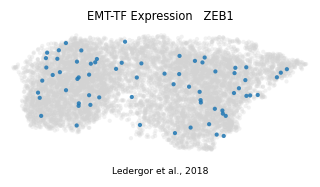

In [5]:
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
show = ok.sort_values('rho_vs_t')['TF'].tolist()
if len(show) == 0: show = [df.sort_values('frac_expr').iloc[-1]['TF']]  # fallback: best-detected
colors = ['tab:blue','tab:red','tab:green','tab:purple']
cmap = {g: colors[i%len(colors)] for i,g in enumerate(show)}
thr = {}
for g in show:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in show}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in show},
      '| cells shown:', {g: int(sel[g].sum()) for g in show})
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
order = sorted(show, key=lambda g: -int(sel[g].sum()))
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    if ap.n_obs: sc.pl.umap(ap, na_color=cmap[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
lab = '  '.join(f'{g}' for g in show)
ax.set_title(f'EMT-TF Expression   {lab}', size=7.5)
ax.text(.5,-.14,'Ledergor et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in show:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')